# 07 · Baselines and model comparisons (task 7)

A language model's signal is only interesting if it beats what is cheap. This notebook builds the
three benchmarks and compares every text signal, the LLMs included, with **the same events, the same
outcomes, the same metrics and the same chronological split**.

| Baseline | What it knows | Trained? | Code |
|---|---|---|---|
| **Surprise only** | did the firm beat consensus, and by how much | 10 decile means | `baseline_surprise.py` |
| **Loughran–McDonald** | counts of finance-specific positive / negative words | no | `baseline_lm.py` |
| **TF-IDF + ridge / logit** | which words and word pairs went with high returns in the past | yes, out of sample | `baseline_tfidf.py` |

Then, for each text signal, **surprise-only vs text-only vs combined** (`compare.py`).

> **Reading guide.** A text signal is useful if *combined* beats *surprise-only* out of sample:
> positive `oos_r2_vs_surprise`, Clark–West `cw_t_nw` clearly above 2, and a higher IC than
> surprise-only. A high *text-only* IC alone means little: most of it is the text repeating the
> surprise.

In [1]:
# --- Setup (same in every notebook) ----------------------------------------
import os, sys, warnings
from pathlib import Path

import importlib

# Find the checkout from the repository root or any notebook subfolder; the roots
# come from scripts/project_paths.py, like every other part.
_start = Path(os.environ.get("S08_ROOT", Path.cwd())).expanduser().resolve()
REPO_ROOT = next((p for p in (_start, *_start.parents)
                  if (p / "scripts" / "project_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the cloned S08 repository, "
                            "or set S08_ROOT to its path.")
sys.path.insert(0, str(REPO_ROOT / "scripts"))
import project_paths
importlib.reload(project_paths)
from project_paths import REPO_ROOT, TEAM_DIR, NOV2_DATA, STEP78_DIR, STEP78_CODE

# Notebook paths.
ROOT = STEP78_DIR
while str(STEP78_CODE) in sys.path:
    sys.path.remove(str(STEP78_CODE))
sys.path.insert(0, str(STEP78_CODE))

# SYNTHETIC = True runs everything on fake data with a planted effect and writes to
# results/_synthetic/ (never over the real results). Set STEP78_SYNTHETIC=1 or edit here.
SYNTHETIC = os.environ.get("STEP78_SYNTHETIC", "0") == "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

import settings as S
if SYNTHETIC:
    S.redirect_outputs("synthetic")
S.ensure_dirs()
import io_inputs as IO, outputs as OUT, pipeline as P
print("TEAM_DIR :", S.TEAM_DIR)
print("outputs  :", S.RESULTS)
print("mode     :", "SYNTHETIC DEMO" if SYNTHETIC else "real data")

TEAM_DIR : /Users/maximelacroix/Downloads/S08 NLP
outputs  : /Users/maximelacroix/Downloads/S08 NLP/7_8_baselines_evaluation/results
mode     : real data


In [2]:
ev, texts, sectors, scores, prov = P.load_all(SYNTHETIC)
panel = P.build_inputs(ev, texts, sectors)
P.describe_panel(panel)

texts: 111 cleaned documents from 1 year files in /Users/maximelacroix/Downloads/S08 NLP/5_data cleaning/data/clean
texts: 98 more from the fallback export release_texts.csv (not cleaned by part 5: use for development only)


sectors: 100.0% of events have a point-in-time SIC
model scores: the cache is empty (part 6 has not run)
panel: 217,611 events -> 69,028 in sample 'in_primary' without 2020
holdout guard: dropped 22,145 rows from 2021-2025


,events,with_text,seasons,first,last,median_sue,mean_car_0_1_ff4
split,,,,,,,
dev,35508,105,44,2006-01-04,2016-12-22,0.0005,0.0015
validation,11375,10,12,2017-01-04,2019-12-20,0.0006,0.0005


## 1. Out-of-sample by construction: the chronological folds

Every trained signal is predicted by a model fitted **only on earlier events**, with a 100-day
embargo (so a training label's 60-day return window never reaches into the test period):

* dev years: expanding window (train on years < *y*, predict *y*), used to choose hyper-parameters;
* validation (2017–2019): train on all of dev, predict once. This is the comparison set until the freeze;
* holdout: train on dev + validation, after the freeze only.

Random K-fold would train on the future and leak firm boiler-plate between folds.

In [3]:
from crossfit import describe_folds
describe_folds(panel)

,fold,train_events,train_last_date,embargo_until,test_events,test_first_date
0,dev_2009,7776,2008-09-22,2008-09-23,3197,2009-01-06
1,dev_2010,10839,2009-09-22,2009-09-23,3256,2010-01-06
2,dev_2011,14136,2010-09-22,2010-09-23,3278,2011-01-05
3,dev_2012,17417,2011-09-22,2011-09-23,3238,2012-01-04
4,dev_2013,20711,2012-09-21,2012-09-23,3334,2013-01-03
5,dev_2014,23949,2013-09-20,2013-09-23,3370,2014-01-03
6,dev_2015,27295,2014-09-22,2014-09-23,3747,2015-01-06
7,dev_2016,30993,2015-09-22,2015-09-23,3580,2016-01-05
8,validation,34625,2016-09-23,2016-09-26,11375,2017-01-04


## 2. Baseline 1: the earnings surprise

The benchmark. Part 3's SUE (actual − median point-in-time consensus, over price at t−2). The price
response is **S-shaped**: strong in the tails, almost flat in the middle. We therefore use 10 decile
dummies as the benchmark, not a straight line. Otherwise a text model could "add information" just by
bending the line.

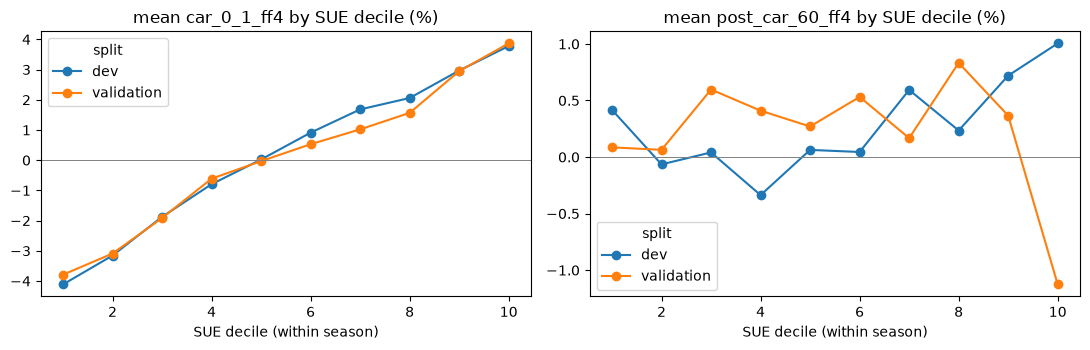

,outcome,n,seasons,mean_ic,ic_t_nw,ls_mean,ls_t_nw,hit_rate,auc
0,car_0_1_ff4,11375,12,0.3136,22.2600,0.0752,13.3293,0.6173,0.6546
1,post_car_1_ff4,11375,12,0.0255,2.4700,0.0022,0.5919,0.5093,0.5143
2,post_car_60_ff4,11375,12,-0.0114,-0.7300,-0.0135,-1.8579,0.5017,0.4972
3,car_1_60_ff4,11375,12,-0.0201,-1.2900,-0.0166,-2.3815,0.4985,0.4947
4,ar_m1,11375,12,0.0360,4.6600,0.0026,4.5402,0.5130,0.5213


In [4]:
from metrics import evaluate_signal
d = panel[panel["split"].isin(["dev", "validation"])]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, oc in zip(ax, ["car_0_1_ff4", "post_car_60_ff4"]):
    m = d.groupby(["split", "sue_decile"])[oc].mean().unstack(0) * 100
    m.plot(ax=a, marker="o"); a.axhline(0, color="grey", lw=.7)
    a.set_title(f"mean {oc} by SUE decile (%)"); a.set_xlabel("SUE decile (within season)")
plt.tight_layout(); OUT.save_figure(fig, "t7_sue_decile_response"); plt.show()

sb = pd.DataFrame([evaluate_signal(panel[panel["split"] == "validation"], "sue_rank", oc)
                   for oc in S.OUTCOMES + S.PLACEBO_OUTCOMES])
sb[["outcome", "n", "seasons", "mean_ic", "ic_t_nw", "ls_mean", "ls_t_nw", "hit_rate", "auc"]]

**How to read it.** `mean_ic` is the average within-season Spearman correlation between SUE and the
outcome; `ls_mean` is the top-decile minus bottom-decile mean return per event. The reaction
(`car_0_1_ff4`) is where SUE matters; the drift windows show how much is left after the release.

Note the **placebo** row (`ar_m1`, the day before the release): SUE has a small positive IC there,
consistent with pre-announcement drift. That is why the text placebo tests in notebook 08 always control
for SUE.

## 3. Baseline 2: Loughran–McDonald tone

Counts of LM positive / negative / uncertainty words in `text_body`, with LM's negation rule for
positive words. `lm_tone = (pos − neg)/(pos + neg)` is the main signal; `lm_negshare = −neg/words` the
Tetlock (2007) variant. Counts are cached per (accession, text hash, dictionary), so a rerun only counts
new or changed texts.

In [5]:
try:
    from baseline_lm import lm_features
    lm = lm_features(texts[texts["accession"].isin(panel["accession"])])
    display(lm[["lm_tone", "lm_net", "lm_negshare", "lm_unc", "n_words"]].describe().T)
except FileNotFoundError as e:
    lm = None
    print("LM baseline not run yet:", e)

LM baseline not run yet: Loughran-McDonald master dictionary not found in resources/lm/. Download the CSV from https://sraf.nd.edu/loughranmcdonald-master-dictionary/ (see resources/lm/README.md).


## 4. Baseline 3: TF-IDF with ridge and logit

Uni- and bigrams, sublinear term frequency, numbers and years masked, and a **firm filter** (a term
must appear in releases of at least 20 distinct firms in the training window) so the model learns news
words, not company and product names. The penalty is chosen on the *dev* pseudo-out-of-sample IC only,
so the validation years stay untouched until the comparison.

In [6]:
from baseline_tfidf import TfidfConfig, tfidf_signals
tx = texts[texts["accession"].isin(panel["accession"])]
tf, tf_det = tfidf_signals(panel, tx, S.PRIMARY_OUTCOME, TfidfConfig(), ("dev", "validation"),
                           return_details=True)
tf_det["tuning"]

TF-IDF: 115 events with text and outcome
  dev_2009: 74 training documents < 500, skipped
  dev_2010: 76 training documents < 500, skipped
  dev_2011: 81 training documents < 500, skipped
  dev_2012: 86 training documents < 500, skipped
  dev_2013: 87 training documents < 500, skipped
  dev_2014: 92 training documents < 500, skipped
  dev_2015: 96 training documents < 500, skipped
  dev_2016: 99 training documents < 500, skipped
  validation: 104 training documents < 500, skipped
TF-IDF: no fold had enough training documents; signals left empty (expected until part 5 has cleaned several years of releases)


""


The largest ridge weights (validation-fold model). Read them as a sanity check: news words
("raised", "below", "impairment") are expected; firm or product names would mean the firm filter failed.

In [7]:
tf_det["top_terms"].groupby("direction").head(15) if len(tf_det["top_terms"]) else "no TF-IDF model fitted yet"

'no TF-IDF model fitted yet'

## 5. Assemble and save every baseline signal

`data/signals.parquet` (one row per event, keyed by `event_id`) is what notebook 08 and parts 9–10 read.
It is row-level and stays in `data/` (git-ignored).

In [8]:
sig, det = P.build_signals(panel, texts)
P.save_signals(sig)
if "tfidf" in det and len(det["tfidf"]["tuning"]):
    OUT.save_table(det["tfidf"]["tuning"], "t7_tfidf_tuning", "TF-IDF penalty, dev pseudo-OOS IC")
    OUT.save_table(det["tfidf"]["top_terms"], "t7_tfidf_top_terms", "Largest TF-IDF ridge weights")
sig.drop(columns="event_id").notna().mean().rename("coverage").to_frame().T

LM baseline skipped: Loughran-McDonald master dictionary not found in resources/lm/. Download the CSV from https://sraf.nd.edu/loughranmcdonald-master-dictionary/ (see resources/lm/README.md).
TF-IDF: 115 events with text and outcome
  dev_2009: 74 training documents < 500, skipped
  dev_2010: 76 training documents < 500, skipped
  dev_2011: 81 training documents < 500, skipped
  dev_2012: 86 training documents < 500, skipped
  dev_2013: 87 training documents < 500, skipped
  dev_2014: 92 training documents < 500, skipped
  dev_2015: 96 training documents < 500, skipped
  dev_2016: 99 training documents < 500, skipped
  validation: 104 training documents < 500, skipped
TF-IDF: no fold had enough training documents; signals left empty (expected until part 5 has cleaned several years of releases)
TF-IDF done in 0s
-> /Users/maximelacroix/Downloads/S08 NLP/7_8_baselines_evaluation/data/signals.parquet (46,883 rows, 12 signals)


,sue_rank,surp_linear__car_0_1_ff4,surp_deciles__car_0_1_ff4,surp_linear__post_car_1_ff4,surp_deciles__post_car_1_ff4,surp_linear__post_car_60_ff4,surp_deciles__post_car_60_ff4,surp_linear__car_1_60_ff4,surp_deciles__car_1_60_ff4,tfidf_ridge__car_0_1_ff4,tfidf_logit__up,tfidf_fold
coverage,1.0000,0.8185,0.8185,0.8185,0.8185,0.8185,0.8185,0.8185,0.8185,0.0000,0.0000,0.0000


## 6. The comparison: surprise-only vs text-only vs combined

For each text signal T (baselines and every LLM signal in part 6's cache), three linear stacks fitted
on past data only:

```
surprise-only   y = SUE deciles
text-only       y = a + c · rank(T)
combined        y = SUE deciles + c · rank(T)
```

evaluated on the validation split, **on the events every signal covers** (common support), so no model
is graded on an easier subset.

In [9]:
from compare import compare_models
sig = P.load_signals_aligned(panel, scores)
TEXTS = P.available_text_signals(sig)
print("text signals:", TEXTS or "none yet (only the surprise benchmark can be evaluated)")
tab, preds = compare_models(panel, sig, TEXTS, S.PRIMARY_OUTCOME, "validation")
cols = ["text_signal", "approach", "n", "mean_ic", "ic_t_nw", "ls_mean", "oos_r2_vs0",
        "oos_r2_vs_surprise", "cw_t_nw", "cw_p", "hit_rate", "auc"]
tab[[c for c in cols if c in tab]]

text signals: none yet (only the surprise benchmark can be evaluated)


compare [car_0_1_ff4, validation]: 11,375 events on common support, 12 seasons


,text_signal,approach,n,mean_ic,ic_t_nw,ls_mean,oos_r2_vs0,hit_rate,auc
0,(none),surprise_only,11375,0.3120,22.1200,0.0752,0.0873,0.6326,0.6531
1,(none),sue_rank (raw signal),11375,0.3136,22.2600,0.0752,NaN,0.6173,0.6546


In [10]:
# Same comparison for every event window, saved to results/tables/t7_compare__<outcome>__validation.*
for oc in S.OUTCOMES:
    t, _ = compare_models(panel, sig, TEXTS, oc, "validation")
    if len(t):
        OUT.save_table(t, f"t7_compare__{oc}__validation", f"Surprise-only vs text-only vs combined, {oc}")

compare [car_0_1_ff4, validation]: 11,375 events on common support, 12 seasons


compare [post_car_1_ff4, validation]: 11,375 events on common support, 12 seasons


compare [post_car_60_ff4, validation]: 11,375 events on common support, 12 seasons


compare [car_1_60_ff4, validation]: 11,375 events on common support, 12 seasons


## 7. What would change the conclusion

* **The comparison set is small**: 12 validation seasons. Treat Clark–West |t| < 3 as weak evidence
  (`docs/METHODOLOGY.md`, section 6). The holdout (20 seasons) decides.
* **Common support matters**: if an LLM covers fewer events (long releases truncated, failed parses),
  the table above is restricted to its events for *every* model. Check `n`.
* **A combined gain only in the reaction window** (`car_0_1_ff4`) and none in the drift windows means
  the text information is *priced in* at release; gains in `post_car_60` would mean it is not.
* **Do the more complex models beat the simple ones?** Compare the LLM rows with the TF-IDF and LM rows
  *in the combined approach*. That is task 7's question, and part 9 asks whether any LLM advantage
  survives after the training cutoff.